# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel.

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


---
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [ ]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [ ]:
# mostrar las primeras 5 filas de plans
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [ ]:
# mostrar las primeras 5 filas de users
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [ ]:
# mostrar las primeras 5 filas de usage
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


In [ ]:
# mostrar las primeras 5 filas de usage
usage.tail(5)

,id,user_id,type,date,duration,length
39995,39996,13497,call,2024-06-29 23:33:56.120903022,5.75,NaN
39996,39997,10941,call,2024-06-29 23:40:27.090677266,3.06,NaN
39997,39998,13038,call,2024-06-29 23:46:58.060451510,8.74,NaN
39998,39999,10863,text,2024-06-29 23:53:29.030225754,NaN,43.0
39999,40000,10759,call,2024-06-30 00:00:00.000000000,1.32,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [ ]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [ ]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [ ]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [ ]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---


## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos


**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [ ]:
# cantidad de nulos para users

print(users.isna().sum())
print(users.isna().mean())


user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [ ]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean())


id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64



En el dataset **users** hay 469 valores nulos en la columna city (11.725%), por lo que se sugiere investigar qué pudo haber pasado con estos registros ya que la ubicación del usuario puede ser un dato importante para la segmentación de los clientes, como en este análisis no tenemos infomració para imputar, los valores se mantendrán como nulos. Además, en la columna churn_date existen 3534 valores nulos (88.35%), lo que nos indica que la mayoría de los usuarios seguían activos para final de semestre de 2024.

En el dataset **usage** tenemos 50 valores nulos en la columna fecha (0.12%) que se pueden mantener como nulos. Por otra parte tenemos 22076 valores nulos en la columna duration y 17896 en la columna length, sin embargo cada registro sólo debería tener datos en una de las 2 columnas, si la interacción es tipo text entonces debe tener un length y si es tipo call debe tener duration, así todos los text (22092) tienen valor en length y todos los call (17908) tienen duration y no tenemos valores nulos.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [ ]:
# explorar columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` tiene el mínimo en 10000 y el máximo en 13999, con una desviación estándar alta, ya que debe haber 4000 valores únicos.
- La columna `age` tiene el mínimo en -999, que ya indica que hay sentinels, máximo en 79 y mediana en 47, valores congruentes con el tipo de variable.

In [ ]:
# explorar columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- La columna `id`corresponde a valores únicos, lo que explica una desviación estándar alta. Así mismo, la columna `user_id` correponde al ID de ususario, en este caso son 4000 usuarios que se pueden repetir al rededor de 10 veces dentro de un conjunto de 40000 registros, razón por lo cual su desviación estándar también es alta.
- Las columnas `duration`y `length`tienen el mínimo en 0, que en el caso de la duración pueden corresponder a llamadas no atendidas, sin embargo, para el caso de la longitud, no tiene sentido un mensaje de texto vacío. La columna`length`contiene 133 (0.6%) registros en 0, que reemplazaremos por valores nulos.
Por otro lado los valores máximos, tanto para `duration`como para `length` están muy alejados del resto de valores. En algunos de los regristros estos valores se pueden eliminar ya que corresponden a datos de duración para text o de longitud para llamada, los demás casos (0.08%) serán analizados más adelante.

In [ ]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
print(users[columnas_user].describe())
print(users['city'].unique())
print(users['city'].value_counts(dropna=False))

          city    plan
count     3531    4000
unique       7       2
top     Bogotá  Basico
freq       808    2595
['Medellín' '?' 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64


- La columna `city` tiene 6 ciudades válidas, 1 sentinel '?' con 96 registros (2.4%) y 469 valores nulos (11.7%).
- La columna `plan` sólo tiene 2 categorías, de las cuales el plan básico representa aproximadamente el 65%.

In [ ]:
 # explorar columna categórica de usage
usage['type'].describe()

count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object

In [ ]:
#Interacciones de tipo texto con valores en duration
usage[(usage['type']=='text') & usage['duration'].notna()].shape[0]

16

In [ ]:
#Interacciones de tipo call con valores en length
usage[(usage['type']=='call') & usage['length'].notna()].shape[0]

12

In [ ]:
#Conteo valores inválidos en length (1490)
usage[usage['length']==1490]['type'].value_counts()

text    18
call    12
Name: type, dtype: int64

In [ ]:
#Cantidad de interacciones con duration de 120
usage[usage['duration']==120]['type'].value_counts()

text    16
call    14
Name: type, dtype: int64

- La columna `type`tiene dos categorías: text y call, donde text es la categoría que aparece con mayor frecuencia (55%)

---
✍️ **Comentario**: Revisando cada una de las variables tanto numéricas como categóricas de los datasets, se encontraron algunos valores inválidos y sentinels que es necesario tratar:
- En la columna 'age' es necesario reemplazar todos los registros inválidos (-999) por la mediana de 'age'.
- En la columna 'city', los sentinels '?' se deben convertir a valores nulos.
- Para el caso de 'duration' existen 16 registros 'text' que tienen asiganada una duración de 120 pero además tienen valor en 'length'; estos valores en 'duration' deben ser eliminados.
- En la columna 'length' se presentala misma situación: existen 12 registros de tipo 'call' con valor en 'duration' y con length de 1490, en estos casos el valor de 1490 sebe ser eliminado; y para los 18 resgistros de tipo 'text' el 1490 en 'length' debe ser eliminado, ya que este valor es muy lejano al resto de valores para esta variable y además porque el límite de caracteres de un SMS estándar es de máximo 160, lo que confirma que este es un valor no válido.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [ ]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'],errors='coerce')
users['reg_date'].head()

0   2022-01-01 00:00:00.000000000
1   2022-01-01 06:34:17.914478619
2   2022-01-01 13:08:35.828957239
3   2022-01-01 19:42:53.743435858
4   2022-01-02 02:17:11.657914478
Name: reg_date, dtype: datetime64[ns]

In [ ]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'],errors='coerce')
usage['date'].head()

0   2024-01-01 00:00:00.000000000
1   2024-01-01 00:06:30.969774244
2   2024-01-01 00:13:01.939548488
3   2024-01-01 00:19:32.909322733
4   2024-01-01 00:26:03.879096977
Name: date, dtype: datetime64[ns]

In [ ]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts(dropna=False)

2024    1330
2023    1316
2022    1314
2026      40
Name: reg_date, dtype: int64

In [ ]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts(dropna=False)

2024.0    39950
NaN          50
Name: date, dtype: int64

✍️ **Comentario**:

- En `reg_date`, existen registros con fecha de 2026, lo cual no es posible porque los datos fueron registrados hasta el 2024. Haciendo un análisis más profundo, los ID cuya reg_date es 2026, cuentan con registros en el dataset usage con fecha de 2024, así que podemos mantener los registros como nulos y asumir que fue un error de captura o registro.
- En `date`, tenemos 39950 registros en 2024 y sólo 50 registros (0.125%) sin fecha, así que podemos mantenerlos como nulos. Basaremos el análisis en estas fechas.


---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [ ]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999,age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [ ]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace("?",pd.NA)

# Verificar cambios
users['city'].isna().sum()

565

In [ ]:

# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT


# Verificar cambios
users['reg_date'].dt.year.unique()

array([2022.,   nan, 2023., 2024.])

### 3.2 Evaluar Valores Nulos o Faltantes
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [ ]:
# Verificación MAR en usage (Missing At Random) para duration
missing_duration_by_type =usage['duration'].isna().groupby(usage['type']).sum()
print(missing_duration_by_type)

type
call        0
text    22076
Name: duration, dtype: int64


In [ ]:
# Verificación MAR en usage (Missing At Random) para length
missing_length_by_type =usage['length'].isna().groupby(usage['type']).sum()
print(missing_length_by_type)

type
call    17896
text        0
Name: length, dtype: int64


Los faltantes en las columnas `duration` y `length`son MAR dependientes de la variable `type`, así las interacciones de tipo 'call' deben tener una duración y las interacciones tipo 'text' una longitud. Así mismo, como ya se había explicado antes, las interacciones tipo 'call' sólo deben tener 'duration', así que cualquier valor en 'length'para una llamada es un valor inválido, y lo mismo pasa con las interacciones tipo 'text' y los valores en 'duration'.

In [ ]:
# Eliminación de valores inválidos en length y duration
usage['duration'] = np.where(usage['type'] == 'text', np.nan, usage['duration'])
usage['length'] = np.where(usage['type'] == 'call', np.nan, usage['length'])

usage.info()
usage.groupby('type')['id'].count()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   id        40000 non-null  int64         
 1   user_id   40000 non-null  int64         
 2   type      40000 non-null  object        
 3   date      39950 non-null  datetime64[ns]
 4   duration  17908 non-null  float64       
 5   length    22092 non-null  float64       
dtypes: datetime64[ns](1), float64(2), int64(2), object(1)
memory usage: 1.8+ MB


type
call    17908
text    22092
Name: id, dtype: int64

Después de la limpieza tenemos 17908 llamadas con su valor de 'duration' y 22092 mensajes con su valor de 'length', para un total de 40000 registros.

In [ ]:
#Limpieza de valores inválidos en la columna length
usage['length'] = np.where((usage['length'] == 0) | (usage['length'] == 1490), np.nan, usage['length'])
usage['length'].describe()

count    21941.000000
mean        50.477371
std         19.556160
min          1.000000
25%         37.000000
50%         50.000000
75%         64.000000
max        125.000000
Name: length, dtype: float64

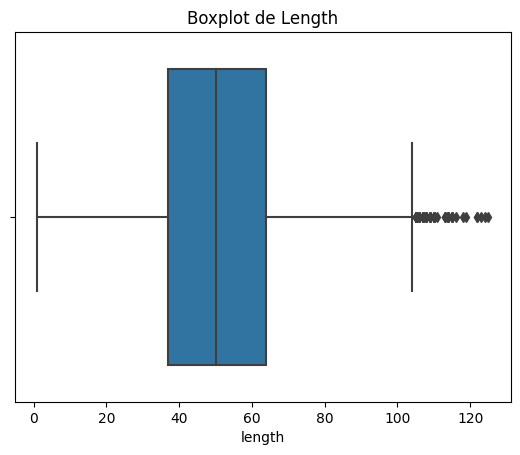

In [ ]:
sns.boxplot(data= usage, x='length')
plt.title('Boxplot de Length')
plt.show()

En la columna length convertimos los valores inválidos 0 y 1490 (151 registros) en valores nulos.
Se decidió no winsorizar, ya que existen otros valores que también están fuera del percentil 1% y 99%, pero de los cuales no tenemos evidencia que nos indique que son inválidos, de hecho eliminando los valores de 1490 el nuevo máximo es de 125 caracteres, valor que está dentro del límite técnico posible de un SMS.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico.

**Instrucciones:**:
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [ ]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = (
    usage.groupby('user_id')[['is_text', 'is_call', 'duration']]
    .sum()
    .reset_index()
)

# Renombrar columnas
usage_agg = usage_agg.rename(columns={'is_text':'cant_mensajes','is_call':'cant_llamadas','duration':'cant_minutos_llamada'})

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = pd.merge(users,usage_agg,on='user_id',how='left')
cols_fill = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
user_profile[cols_fill] = user_profile[cols_fill].fillna(0)
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [ ]:
# Resumen estadístico de las columnas numéricas
user_profile.describe()

,user_id,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000
mean,11999.500000,48.136000,5.523000,4.477000,22.831225
std,1154.844867,17.689919,2.359738,2.145139,16.592068
min,10000.000000,18.000000,0.000000,0.000000,0.000000
25%,10999.750000,33.000000,4.000000,3.000000,11.087500
50%,11999.500000,48.000000,5.000000,4.000000,19.735000
75%,12999.250000,63.000000,7.000000,6.000000,31.182500
max,13999.000000,79.000000,17.000000,15.000000,155.690000


In [ ]:
# Distribución porcentual del tipo de plan
users['plan'].value_counts(normalize=True)

Basico     0.64875
Premium    0.35125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada`

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda)

**Hint**  
Para cada histograma,
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

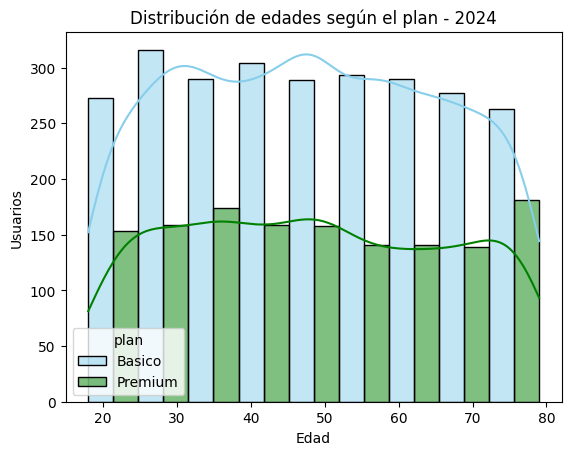

In [ ]:
# Histograma para visualizar la edad (age)

sns.histplot(data= user_profile, x= 'age',hue='plan', bins=9, palette=['skyblue','green'],multiple = 'dodge',kde=True)
plt.title('Distribución de edades según el plan - 2024')

plt.xlabel('Edad')
plt.ylabel('Usuarios')

plt.show()


💡Insights:
- Distribución de la edad, tanto para el plan básico como para el premium, es uniforme, aunque vemos un pequeño pico en Premium para el intervalo de 74 a 79 años.

In [ ]:
user_profile.groupby('plan')[['cant_mensajes','cant_llamadas','cant_minutos_llamada']].agg(['mean','median'])

cant_mensajes        cant_llamadas        cant_minutos_llamada       
                 mean median          mean median                 mean median
plan                                                                         
Basico       5.525626    5.0      4.454721    4.0            22.572909  19.51
Premium      5.518149    5.0      4.518149    4.0            23.308327  20.30

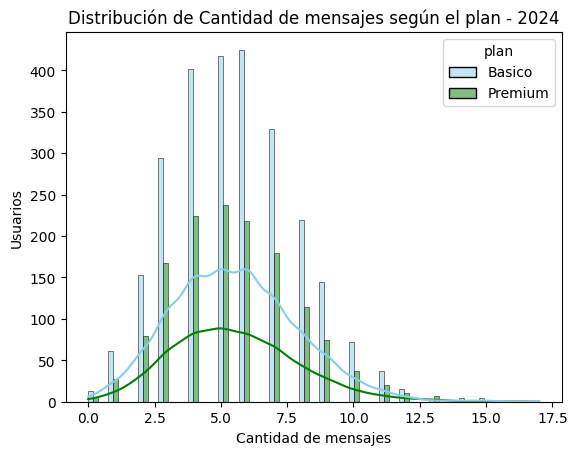

In [ ]:
# Histograma para visualizar la cant_mensajes

sns.histplot(data= user_profile, x= 'cant_mensajes',hue='plan', palette=['skyblue','green'], multiple = 'dodge',kde=True)
plt.title('Distribución de Cantidad de mensajes según el plan - 2024')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Usuarios')
plt.show()

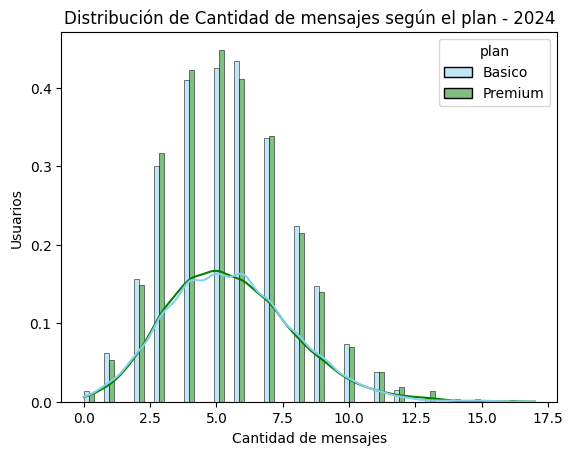

In [ ]:
# Histograma para visualizar la cant_mensajes

sns.histplot(data= user_profile, x= 'cant_mensajes',hue='plan', palette=['skyblue','green'], multiple = 'dodge',kde=True, stat='density', common_norm=False)
plt.title('Distribución de Cantidad de mensajes según el plan - 2024')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Usuarios')
plt.show()

💡Insights:
- La distribución de la cantidad de mensajes enviados durante 2024 es sesgada la derecha, con mínimo en 0 y máximo en 17, con mediana en 5. La distribuciónpresenta patrones muy similares entre los usuarios de los planes Básico y Premium, con una mayor concentración de observaciones entre 3 y 7 mensajes. Las frecuencias absolutas son superiores en el plan Básico, lo cual está relacionado con su mayor participación en la base de usuarios. En ambos planes se observa una menor frecuencia de usuarios con consumos elevados.

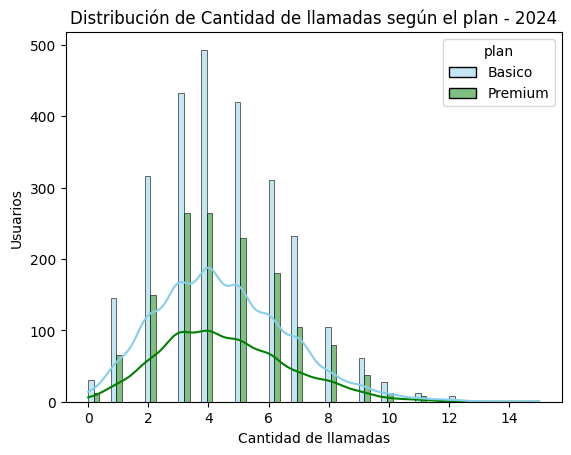

In [ ]:
# Histograma para visualizar la cant_llamadas

sns.histplot(data= user_profile, x= 'cant_llamadas',hue='plan', palette=['skyblue','green'],multiple = 'dodge',kde=True)
plt.title('Distribución de Cantidad de llamadas según el plan - 2024')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Usuarios')
plt.show()

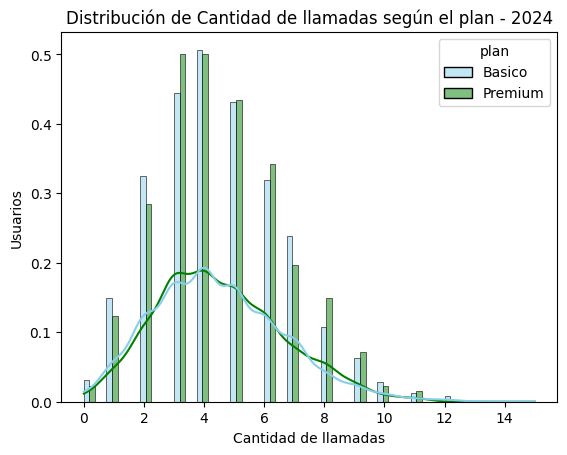

In [ ]:
# Histograma para visualizar la cant_llamadas

sns.histplot(data= user_profile, x= 'cant_llamadas',hue='plan', palette=['skyblue','green'],multiple = 'dodge',kde=True,stat='density', common_norm=False)
plt.title('Distribución de Cantidad de llamadas según el plan - 2024')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Usuarios')
plt.show()

💡Insights:
- La distribución de la cantidad de llamadas durante 2024 también presenta un sesgo a la derecha, con el mínimo en 0, máximo en 15 y mediana en 4. Igual que con la cantidad de mensajes, se observa un patron de distribución bastante similar para los usuarios de Plan Básico y los ususarios con plan Premium.

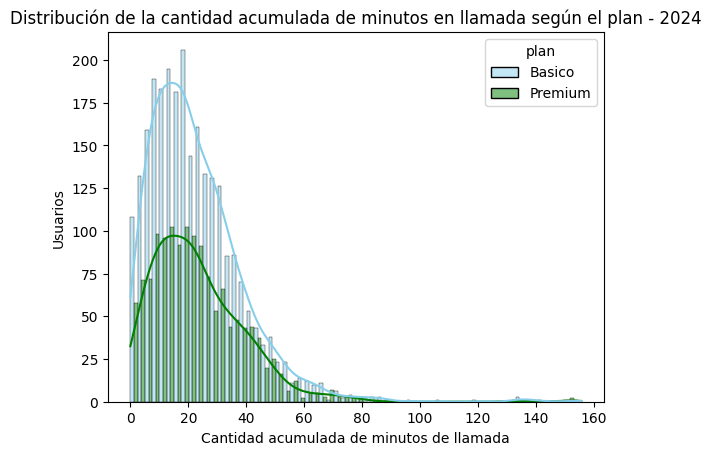

In [ ]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data= user_profile, x= 'cant_minutos_llamada',hue='plan', palette=['skyblue','green'],multiple = 'dodge',kde=True)
plt.title('Distribución de la cantidad acumulada de minutos en llamada según el plan - 2024')
plt.xlabel('Cantidad acumulada de minutos de llamada')
plt.ylabel('Usuarios')
plt.show()

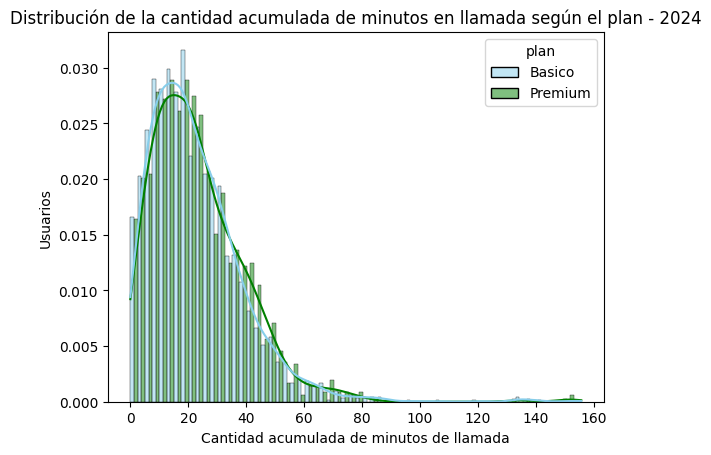

In [ ]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data= user_profile, x= 'cant_minutos_llamada',hue='plan', palette=['skyblue','green'],multiple = 'dodge',kde=True, stat='density', common_norm=False)
plt.title('Distribución de la cantidad acumulada de minutos en llamada según el plan - 2024')
plt.xlabel('Cantidad acumulada de minutos de llamada')
plt.ylabel('Usuarios')
plt.show()

💡Insights:
- La distribución de la cantidad total acumulada de minutos en llamada para el primer semestre de 2024, presenta un sesgo a la derecha, con mínimo en 0, máximo en 155.69 y mediana en 19.7. El comportamiento de las distribuciones para el Plan básico y el Plan premium son bastante similares, con medias en 22.57 y 23.31 y medianas en 19.51 y 20.30 respectivamente.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age`
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

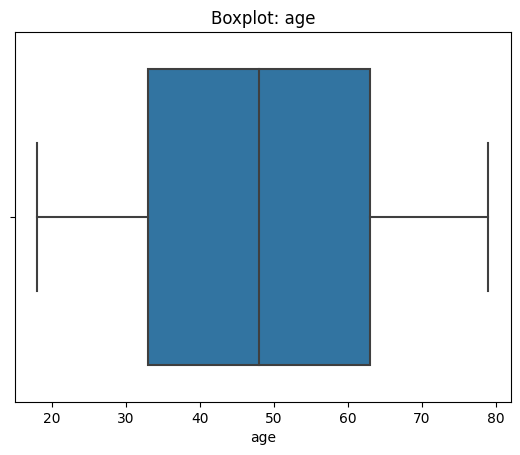

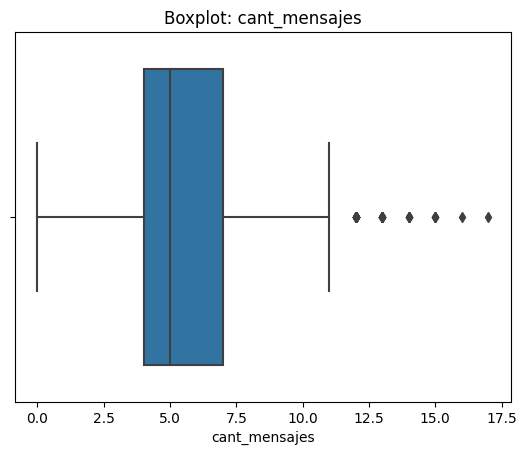

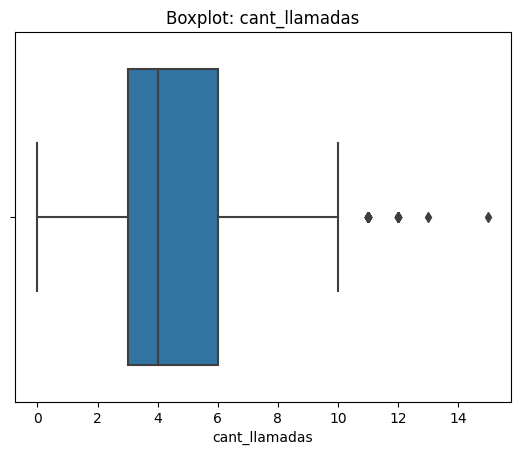

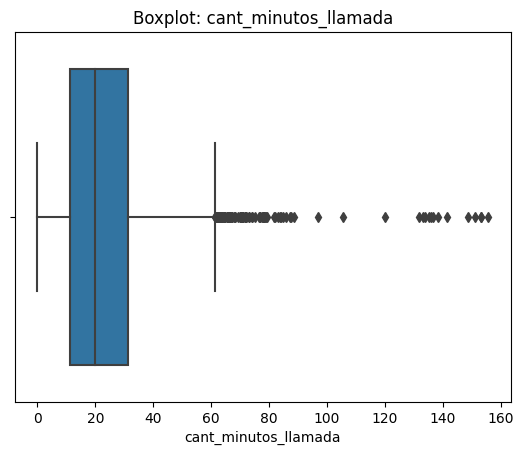

In [ ]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data= user_profile, x= col)
    plt.title(f'Boxplot: {col}')
    plt.show()

In [ ]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3-Q1
    upper = Q3+1.5*IQR
    cant_outliers = (user_profile[col] > upper).sum()
    print(f'Upper de {col}:{upper}')
    print(f'Número de outliers: {cant_outliers}')
    print()

Upper de cant_mensajes:11.5
Número de outliers: 46

Upper de cant_llamadas:10.5
Número de outliers: 30

Upper de cant_minutos_llamada:61.324999999999996
Número de outliers: 96



💡Insights:
- Age: no presenta outliers
- cant_mensajes: presenta 46 outliers superiores
- cant_llamadas: presenta 30 outliers superiores
- cant_minutos_llamada: presenta 96 outliers superiores

In [ ]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,22.831225
std,2.359738,2.145139,16.592068
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.087500
50%,5.000000,4.000000,19.735000
75%,7.000000,6.000000,31.182500
max,17.000000,15.000000,155.690000


💡Insights:
- cant_mensajes: Mantener outliers, aunque la mediana sea 5 y el límite 11, hasta 17 mensajes en un periodo de seis meses es un valor bastante posible. Además no existe evidencia de que haya un error en la captura de los datos, esto sólo nos indica que hay un grupo de ususarios que tiene una actividad mucho mayor.
- cant_llamadas: Mantaner outliers, aunque la mediana sea 4 y el límite sea 10, hasta 15 llamadas en un periodo de seis meses es un valor bastante posible. Además todas las llamadas cuentan con registro completo (id, fecha, duración), por lo que no existe evidencia de que haya un error en la captura de los datos, esto sólo nos indica que hay un grupo de ususarios que tiene una actividad mucho mayor.
- cant_minutos_llamada: Mantener outliers, aunque el límite de la cantidad de minutos de llamada sea 61, un máximo de 155.69 minutos acumulados en seis meses es un valor bastante posible. En el regristo original de las llamadas se encontraron 14 llamadas con duración de 120 minutos que pueden estar alterando el valor total de minutos en llamada por usuario, y aunque parece un valor sospechoso no hay suficiente evidencia que indique que no es real.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [ ]:
# Crear columna grupo_uso

user_profile['grupo_uso'] = np.where((user_profile['cant_llamadas']<5)&(user_profile['cant_mensajes']<5),'Bajo uso',
                                    np.where((user_profile['cant_llamadas']<10)&(user_profile['cant_mensajes']<10),'Uso medio','Alto uso'))


In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [ ]:
# Crear columna grupo_edad
user_profile['grupo_edad'] = np.where(user_profile['age']<30,'Joven',
                                    np.where(user_profile['age']<60,'Adulto','Adulto Mayor'))

In [ ]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

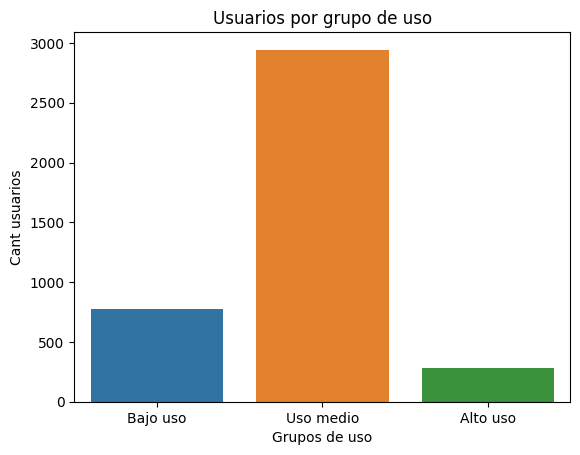

In [ ]:
# Visualización de los segmentos por uso

sns.countplot(data=user_profile,x='grupo_uso',order=['Bajo uso','Uso medio','Alto uso'])
plt.title('Usuarios por grupo de uso')
plt.xlabel('Grupos de uso')
plt.ylabel('Cant usuarios')
plt.show()

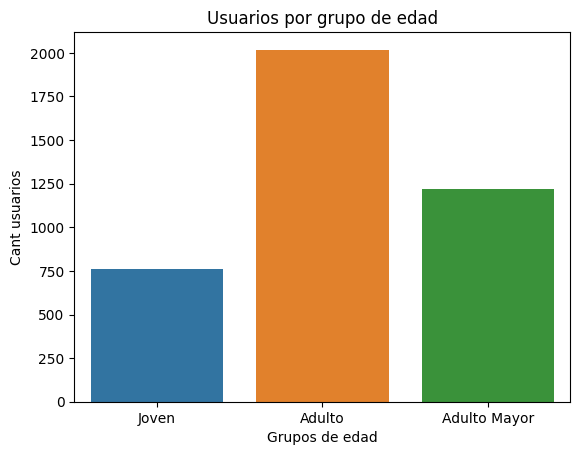

In [ ]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile,x='grupo_edad', order=['Joven','Adulto','Adulto Mayor'])
plt.title('Usuarios por grupo de edad')
plt.xlabel('Grupos de edad')
plt.ylabel('Cant usuarios')
plt.show()

💡La mayoría de los usuarios con Adultos (50.4%) y la mayoría de los usuarios muestran un uso medio del servicio (73.6%)

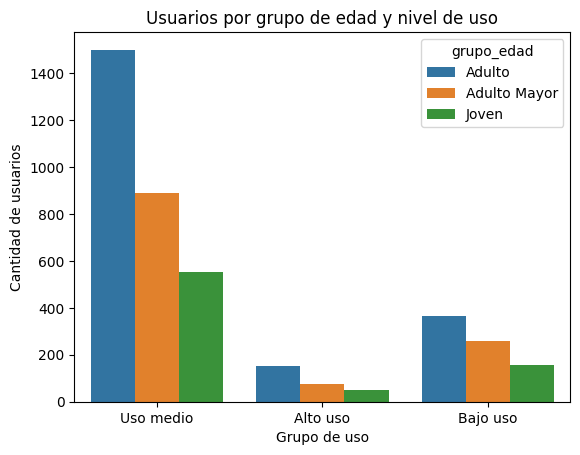

In [ ]:
#Usuarios por grupo de uso y edad
sns.countplot(data=user_profile,x='grupo_uso',hue='grupo_edad')

plt.title('Usuarios por grupo de edad y nivel de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Se observa que para todos los grupos de uso, la distribución por grupo de edad es similar, siendo el grupo de adultos el que más usuario tiene para todos los grupos de uso, seguido del grupo de adultos mayores y finalmente el grupo de jóvenes.

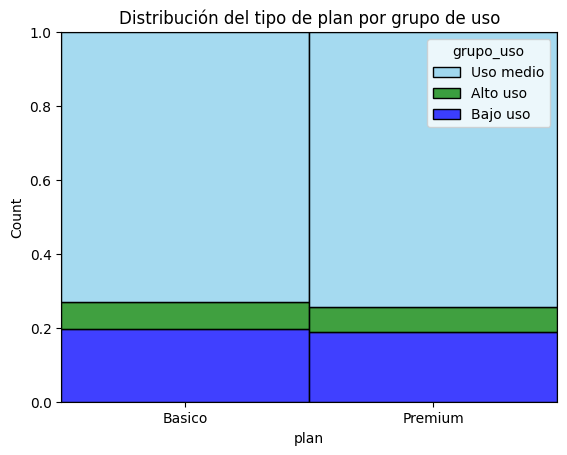

In [ ]:
#
sns.histplot(data= user_profile, x='plan' ,hue='grupo_uso', palette=['skyblue','green','blue'], multiple='fill')
plt.title('Distribución del tipo de plan por grupo de uso')
plt.show()

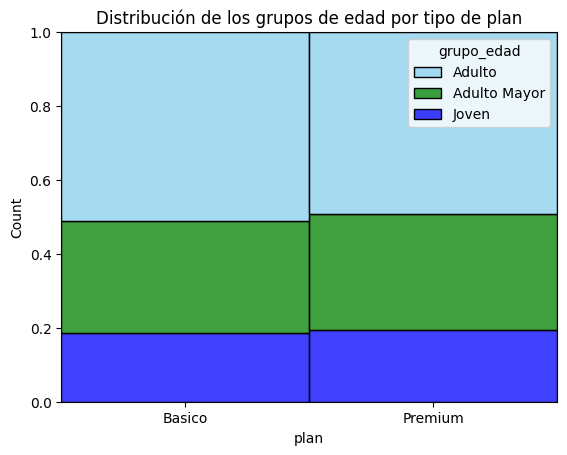

In [ ]:
sns.histplot(data= user_profile, x='plan' ,hue='grupo_edad', palette=['skyblue','green','blue'], multiple= 'fill')
plt.title('Distribución de los grupos de edad por tipo de plan')
plt.show()

💡 Se observa que las distribuciones de usuarios (proporcionalmente) por grupo de edad y por grupo de uso para cada tipo de plan son también bastante similares.

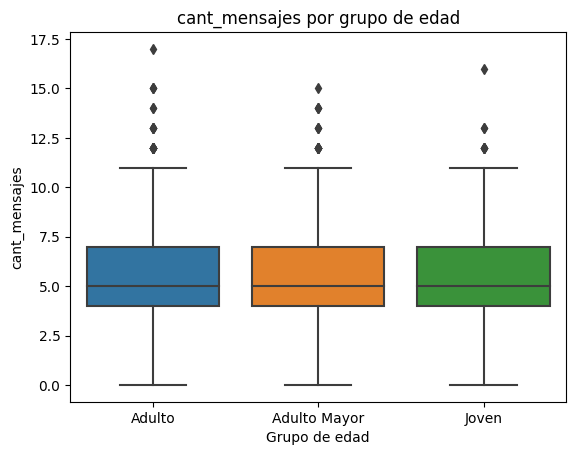

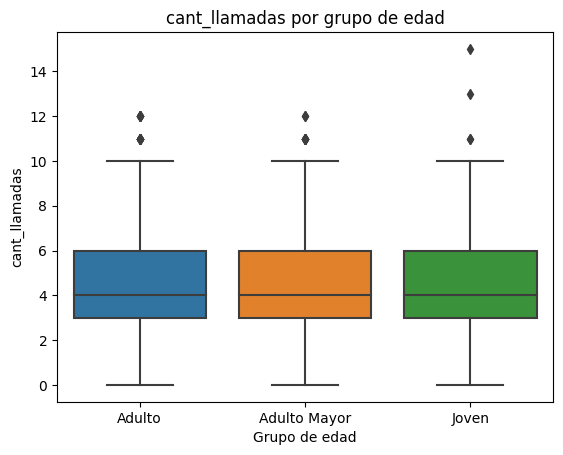

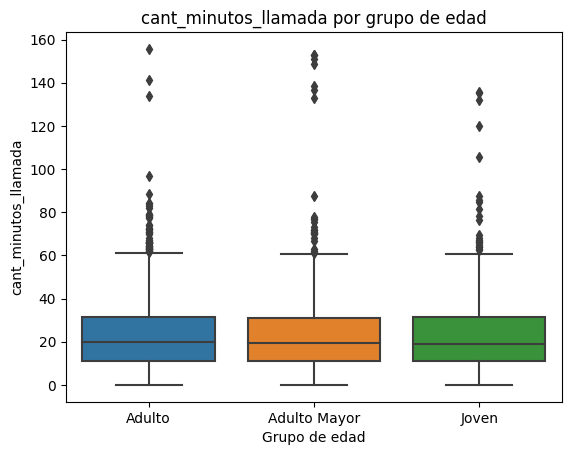

In [ ]:
variables = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for variable in variables:
    sns.boxplot(data=user_profile,x='grupo_edad', y=variable)

    plt.title(f'{variable} por grupo de edad')
    plt.xlabel('Grupo de edad')
    plt.ylabel(variable)
    plt.show()

- Las distribuciones de la cantidad de llamadas, de mensajes y la cantidad de minutos según el grupo de edad también son similares para el grueso de los datos. Sólo se observan algunas variaciones en los máximos y cantidad de outliers: para la cantidad de mensajes encontramos que el grupo de los adultos muestra valores más extremos, para la cantidad de llamadas es en el grupo de los jóvenes donde están los usuarios con mayor número de llamadas acumuladas, y en la cantidad de minutos total el máximo valor está en el grupo de los adultos, pero los adultos mayores muestras mayor cantidad de valores extremos por encima de los 120 minutos.

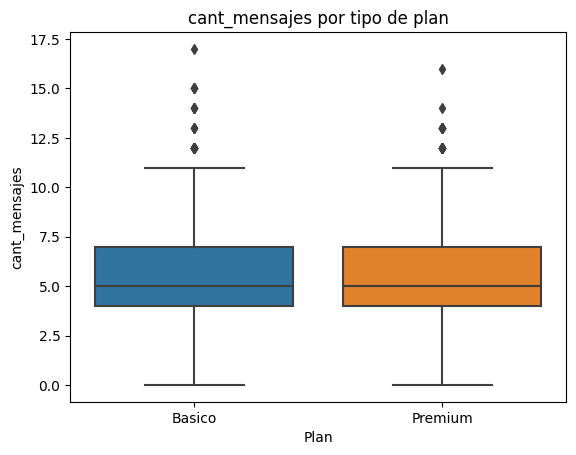

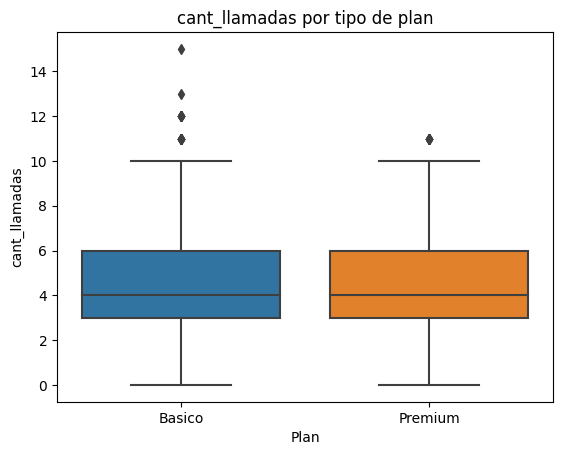

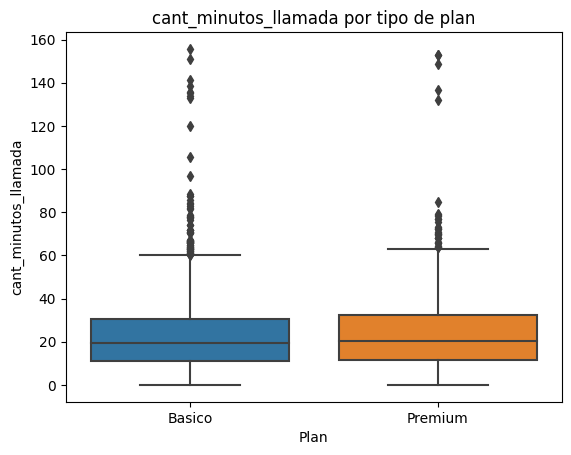

In [ ]:
for variable in variables:
    sns.boxplot(data=user_profile,x='plan', y=variable)

    plt.title(f'{variable} por tipo de plan')
    plt.xlabel('Plan')
    plt.ylabel(variable)
    plt.show()

- Las distribuciones de la cantidad de llamadas, de mensajes y la cantidad de minutos según el tipo de plan también son similares para el grueso de los datos. Sólo se observan algunas variaciones en los máximos y cantidad de outliers: para cantidad de mensajes, los usuarios con plan básico muestran el máximo más alto y mayor número de outliers; en cuanto a la cantidad de llamadas hay una diferencia más notable en los valores extremos, siendo el plan básico el que muestra más outliers y con un máximo mayor; y para la cantidad total de minutos hablados nuevamente el plan básico muestra mayor cantidad de outliers y un máximo más alto que el del plan premium.

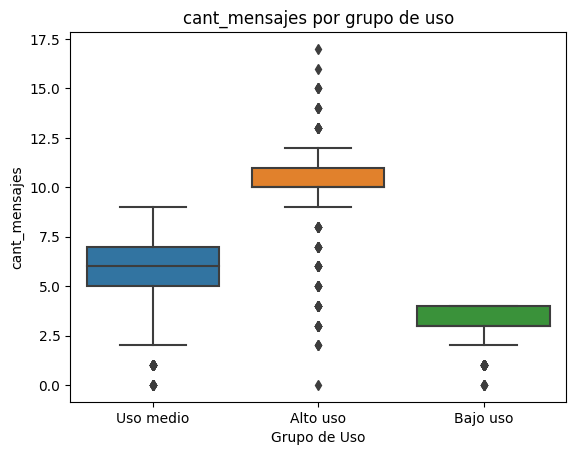

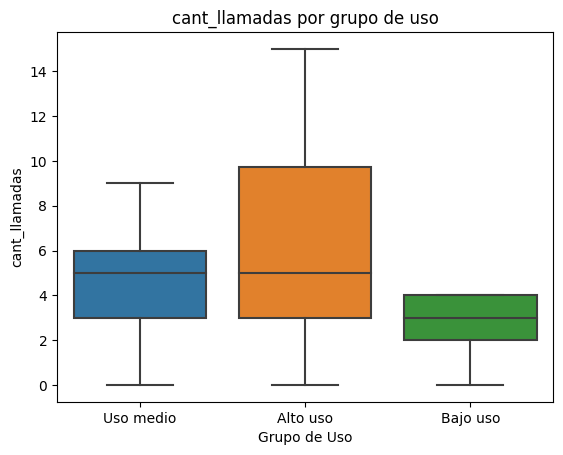

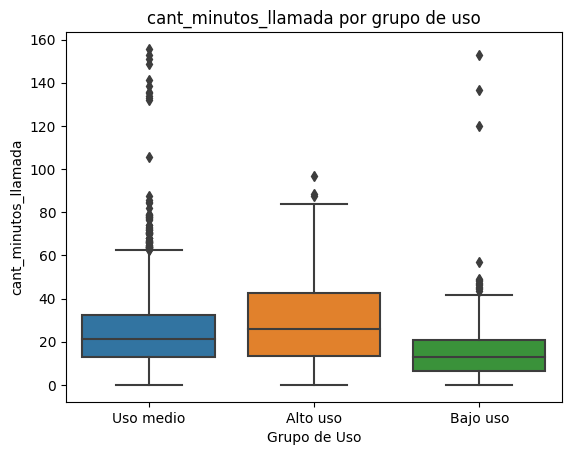

In [ ]:
for variable in variables:
    sns.boxplot(data=user_profile,x='grupo_uso', y=variable)

    plt.title(f'{variable} por grupo de uso')
    plt.xlabel('Grupo de Uso')
    plt.ylabel(variable)
    plt.show()

In [ ]:
#Duración promedio de una llamada según grupo de uso
(user_profile['cant_minutos_llamada'] / user_profile['cant_llamadas'].replace(0, np.nan)).groupby(user_profile['grupo_uso']).mean()

grupo_uso
Alto uso     4.985117
Bajo uso     5.424572
Uso medio    5.076243
dtype: float64

- Como era de esperarse, dado que la segmentación por grupo de uso está definida por la cantidad de llamadas y de mensajes, aquí sí notamos variaciones en las distribuciones según el grupo de uso.
Para la cantidad de mensajes, en el grupo de Alto uso, los valores se concentran entre 10 y 11 mensajes, con outliers tanto en el extremo inferior como en el extremo superior, con el mínimo en 0 y el máximo en 17; y en los grupos de uso medio y bajo se presentan outliers en el extremo inferior con el mínimo el 0 para ambos casos.
Para la cantidad de llamadas no tenemos valores atípicos o outliers en ninguno de los grupos de uso, todos los grupos con mínimo en 0.
Y finalmente para la cantidad total de minutos, se observan outliers en los tres grupos de uso, con la salvedad de que el grupo de uso medio es el que muestra mayor cantidad de outliers y el máximo valor extremo de los tres grupos. Podemos inferir que el grupo de alto uso hace mayor cantidad de llamadas pero las llamadas del grupo de uso medio y bajo tienen una mayor duración.

In [ ]:
variables = ['grupo_uso', 'plan']

for variable in variables:
    print(f'\nDistribución de {variable} según grupo_edad:')
    display(
        pd.crosstab(
            user_profile['grupo_edad'],
            user_profile[variable],
            normalize='index',
            margins=True
        ).round(3) * 100
    )


Distribución de grupo_uso según grupo_edad:


grupo_uso,Alto uso,Bajo uso,Uso medio
grupo_edad,,,
Adulto,7.6,18.1,74.3
Adulto Mayor,6.1,21.0,72.9
Joven,6.7,20.7,72.6
All,7.0,19.5,73.6



Distribución de plan según grupo_edad:


plan,Basico,Premium
grupo_edad,,
Adulto,65.7,34.3
Adulto Mayor,64.2,35.8
Joven,63.9,36.1
All,64.9,35.1


In [ ]:
variables = ['grupo_edad', 'plan']

for variable in variables:
    print(f'\nDistribución de {variable} según grupo_uso:')
    display(
        pd.crosstab(
            user_profile['grupo_uso'],
            user_profile[variable],
            normalize='index',
            margins=True
        ).round(3) * 100
    )


Distribución de grupo_edad según grupo_uso:


grupo_edad,Adulto,Adulto Mayor,Joven
grupo_uso,,,
Alto uso,55.0,26.6,18.3
Bajo uso,46.9,33.0,20.2
Uso medio,51.0,30.3,18.8
All,50.4,30.6,19.0



Distribución de plan según grupo_uso:


plan,Basico,Premium
grupo_uso,,
Alto uso,66.5,33.5
Bajo uso,65.9,34.1
Uso medio,64.5,35.5
All,64.9,35.1


In [ ]:

#Preferencia o uso de llamadas y mensajes por grupo de edad
user_profile.groupby( ['grupo_edad'])[['cant_llamadas', 'cant_mensajes']].sum().pipe(lambda df: df.div(df.sum(axis=1), axis=0) * 100).round(2)


,cant_llamadas,cant_mensajes
grupo_edad,,
Adulto,44.69,55.31
Adulto Mayor,45.08,54.92
Joven,44.49,55.51


In [ ]:
#Preferencia o uso de llamadas y mensajes por grupo de uso
user_profile.groupby( ['grupo_uso'])[['cant_llamadas', 'cant_mensajes']].sum().pipe(lambda df: df.div(df.sum(axis=1), axis=0) * 100).round(2)


,cant_llamadas,cant_mensajes
grupo_uso,,
Alto uso,38.34,61.66
Bajo uso,47.27,52.73
Uso medio,45.29,54.71


In [ ]:


user_profile.groupby(
    ['grupo_uso', 'grupo_edad']
)[['cant_llamadas', 'cant_mensajes']].sum().pipe(
    lambda df: df.div(df.sum(axis=1), axis=0) * 100
).round(2)



cant_llamadas  cant_mensajes
grupo_uso grupo_edad                                
Alto uso  Adulto                38.36          61.64
          Adulto Mayor          37.23          62.77
          Joven                 39.88          60.12
Bajo uso  Adulto                47.53          52.47
          Adulto Mayor          46.88          53.12
          Joven                 47.32          52.68
Uso medio Adulto                45.25          54.75
          Adulto Mayor          45.73          54.27
          Joven                 44.69          55.31

In [ ]:
# Estimación de los ingresos mensuales (USD $) según el número de usuarios por tipo de plan
# No se calculan cargos extra porque ningún usuario supera la cantidad de llamadas o mensajes incluídos en su plan
user_profile['ingreso_facturado'] = np.where(user_profile['plan']=="Basico",12,25)
user_profile.groupby(['plan'])[['ingreso_facturado']].sum()

,ingreso_facturado
plan,
Basico,31140
Premium,35125


In [ ]:
#Ingresos facturados mensuales por segmentos de usuarios (grupo_edad-plan)
matriz_ingresos = pd.pivot_table(
    user_profile,
    values='ingreso_facturado',
    index='grupo_edad',
    columns='plan',
    aggfunc='sum',
    fill_value=0,
    margins=True,
    margins_name='Total'
)
display(matriz_ingresos)

plan,Basico,Premium,Total
grupo_edad,,,
Adulto,15900,17325,33225
Adulto Mayor,9408,10950,20358
Joven,5832,6850,12682
Total,31140,35125,66265


In [ ]:
# Proporción del ingreso total mensual por segmento de usuarios (grupo_edad-plan)
matriz_proporcion = (
    pd.pivot_table(
        user_profile,
        values='ingreso_facturado',
        index='grupo_edad',
        columns='plan',
        aggfunc='sum',
        fill_value=0,
        margins=True,
        margins_name='Total'
    )
    / user_profile['ingreso_facturado'].sum()
    * 100
).round(2)

display(matriz_proporcion)

plan,Basico,Premium,Total
grupo_edad,,,
Adulto,23.99,26.15,50.14
Adulto Mayor,14.20,16.52,30.72
Joven,8.80,10.34,19.14
Total,46.99,53.01,100.00


In [ ]:
# Proporción de usuarios por segmento (grupo_edad-plan)
matriz_proporcion = (
    pd.pivot_table(
        user_profile,
        values='user_id',
        index='grupo_edad',
        columns='plan',
        aggfunc='count',
        fill_value=0,
        margins=True,
        margins_name='Total'
    )
    / user_profile['user_id'].count()
    * 100
).round(2)

display(matriz_proporcion)

plan,Basico,Premium,Total
grupo_edad,,,
Adulto,33.12,17.32,50.45
Adulto Mayor,19.60,10.95,30.55
Joven,12.15,6.85,19.00
Total,64.88,35.12,100.00



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:**
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- En el dataset **users** hay 469 (11.72%) valores nulos y 96 (2.4%) sentinels en la columna city , 3534 valores nulos (88.35%) en la columna churn_date, y 55 (1.38%) valores inválidos (-999) en la columna age que fueron imputados con la mediana. Además, en reg_date había 40 (1%) usarios con fecha de registro en el año 2026, sin embargo, revisando estos ID's en el dataset de usage se encontraron registros de llamadas y mensajes de 2024, así que se infiere que se trata de un error de captura, se convirtieron en nulos y se incluyeron en el análisis.

- En el dataset **usage** se encontraron 50 valores nulos en la columna date (0.12%). Por otra parte había 22076(55.19%) valores nulos en la columna duration y 17896(44.74%) en la columna length, sin embargo estas variables son dependientes del tipo de interacción ('type'), así que los text (22092) sólo deben tener valor en length y todos los call (17908) deben tener duration. Adicionalmente, para el caso de las interacciones de tipo texto, en la variable 'length', se detectaron 151 registros con valores no válidos en 0 y 1490 que se reemplazaron por valores nulos.


🔍 **Segmentos por Edad**
- El rango de edad de los usuarios va de 18 a 79 años, y se segmentaron en 3 grupos: Joven (18-29 años), Adulto(30-59 años) y Adulto Mayor (60-79 años). Se encontró que la mayoría de los usuarios son Adultos entre los 30 y 59 años con el 50.4%, el 30.6% son adultos mayores y el 19% son jóvenes.
- No se observa una diferencia entre las proporciones por grupo de uso, plan de telefonía o preferencias entre llamadas y mensajes dependiendo del grupo de edad, es decir se mantienen las mismas proporciones para los 3 grupos de edad: Bajo uso (19.5%), Uso medio (73.6%), Alto uso (7.0%) | Premium (35.1%), Básico (64.9%) | Llamadas (45%), Mensajes (55%)


📊 **Segmentos por Nivel de Uso**
- Se segmentaron los usuarios de acuerdo a la cantidad de interacciones registradas en el primer semestre de 2024. Bajo uso: llamadas<5 & mensajes<5, Uso medio: llamadas<10 & mensajes<10, Alto uso: para el resto de los casos. El 19.5% de los usuarios tiene un uso Bajo, el 73.6% un Uso medio y el 7% un uso Alto.
- Desde la perspectiva del Nivel de uso se observan ligeras variaciones en las proporciones de usuarios por grupo de edad o preferencia de interacción:
  *Bajo uso: Joven (20.2%), Adulto (46.9%), Adulto Mayor (33.0%) | Uso medio: Joven (18.8%), Adulto (51.0%), Adulto Mayor (30.3%) | Alto uso: Joven (18.3%), Adulto (55.0%), Adulto Mayor (26.6%)
  *Bajo uso: Mensajes (52.7%), llamadas (47.3%) | Uso medio: Mensajes (54.7%), llamadas (45.3%) | Alto uso: Mensajes (61.7%), llamadas (38.4%)

➡️ Esto sugiere que para ConnectaTel el segmento de usuarios más importante es el de los adultos entre 30 y 59 años, ya que representa el 50.4% de los usuarios. Por otra parte, aunque el 64.9% de los usuarios contrató el plan básico, los usuarios premium aportan el 53% de los ingresos, así que los dos tipos de usuario son igual de importantes para la compañía. El 33.1% de los usuarios son adultos-básico y aportan el 24% de los ingresos, mientras que los adultos-premium representan el 17.32% de los usuarios y aportan el 26.2% de los ingresos, siendo el segmento que más aporta. Los jóvenes-básico son el 12.2% de los usuarios y aportan el 8.8% de los ingresos.
También se observa una preferencia de uso de los mensajes de texto sobre las llamadas con el 55%.

En cuanto a los outliers, para las variables de cantidad de llamadas, cantidad de mensajes y duración total de las llamadas, se encontraron valores bastante alejados de la mayoría de los datos, sin embargo no se encontró evidencia suficiente que indicara que el comportamiento no era real. Eso indica que hay un grupo pequeño de usuarios que presenta un uso mucho mayor de los servicios, aunque siguen estando muy por debajo de lo que ofrece cada uno de los planes.

💡 **Recomendaciones**
- Priorizar la retención y fidelización de los usuarios Adulto-Premium, ya que tienen un valor económico significativamente mayor para la compañía.
- Implementar estrategias de reactivación para usuarios de bajo uso, segmento que representa aproximadamente el 19% de la base. Se recomienda analizar su relación con el churn antes de definir acciones específicas.
- Fortalecer las soluciones orientadas a mensajería, dado que los mensajes representan el 55% de las interacciones y alcanzan el 62% entre los usuarios de alto uso

Link a repositorio público del proyecto: https://github.com/lauracmh/ConnectaTel_analysis